Practica 8 prediccion de trafico

Se usa regresion para estimar el volumen de trafico de las siguientes 24 horas del dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

path = "../data/procesed/metro.csv"
metro = pd.read_csv(path, parse_dates=["date_time"])
metro.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40.0,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75.0,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90.0,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90.0,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75.0,Clouds,broken clouds,2012-10-02 13:00:00,4918


Datos para el modelo

Se ordenan las fechas y se deja un registro por hora
Se usan hora, dia de la semana y mes porque tambien se conocen para fechas futuras

In [2]:
datos = metro.dropna(subset=["date_time", "traffic_volume"])
datos = datos.sort_values("date_time").drop_duplicates(subset="date_time")

def calendario(fechas):
    return pd.DataFrame({
        "hora": fechas.dt.hour,
        "dia_semana": fechas.dt.dayofweek,
        "mes": fechas.dt.month
    })

x = calendario(datos["date_time"])
y = datos["traffic_volume"]
corte = int(len(datos) * 0.8)
x_train, x_test = x.iloc[:corte], x.iloc[corte:]
y_train, y_test = y.iloc[:corte], y.iloc[corte:]

x_train.shape, x_test.shape

((32460, 3), (8115, 3))

Modelo de regresion

Se entrena con el primer 80% y se prueba con el ultimo 20% sin mezclar las fechas

In [3]:
modelo = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=5, random_state=42
)
modelo.fit(x_train, y_train)
y_pred = modelo.predict(x_test)

Evaluacion

MAE y RMSE muestran el error en vehiculos por hora
Un r2 mas cercano a 1 indica un mejor ajuste

mae 270.04
rmse 475.32
r2 0.942


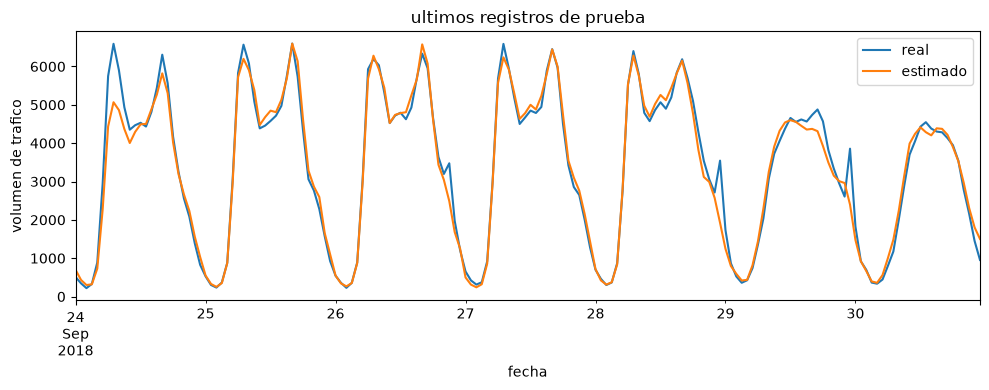

In [4]:
print("mae", round(mean_absolute_error(y_test, y_pred), 2))
print("rmse", round(mean_squared_error(y_test, y_pred) ** 0.5, 2))
print("r2", round(r2_score(y_test, y_pred), 3))

comparacion = pd.DataFrame({
    "real": y_test.to_numpy(),
    "estimado": y_pred
}, index=datos["date_time"].iloc[corte:])

comparacion.tail(168).plot(figsize=(10, 4))
plt.xlabel("fecha")
plt.ylabel("volumen de trafico")
plt.title("ultimos registros de prueba")
plt.tight_layout()
plt.show()

Prediccion futura

Se vuelve a entrenar con todos los datos y se estiman las siguientes 24 horas desde la ultima fecha registrada

In [5]:
modelo.fit(x, y)
fechas = pd.Series(pd.date_range(
    start=datos["date_time"].max() + pd.Timedelta(hours=1),
    periods=24, freq="h"
))
futuro = pd.DataFrame({
    "fecha": fechas,
    "trafico_estimado": modelo.predict(calendario(fechas)).round().astype(int)
})
futuro

,fecha,trafico_estimado
0,2018-10-01 00:00:00,534
1,2018-10-01 01:00:00,337
2,2018-10-01 02:00:00,258
3,2018-10-01 03:00:00,327
4,2018-10-01 04:00:00,832
5,2018-10-01 05:00:00,2715
6,2018-10-01 06:00:00,5635
7,2018-10-01 07:00:00,6410
8,2018-10-01 08:00:00,5683
9,2018-10-01 09:00:00,4893


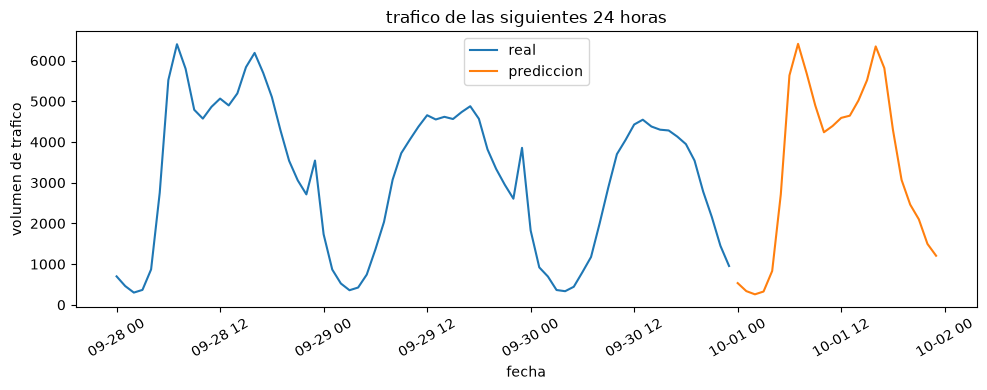

In [6]:
historial = datos.set_index("date_time")["traffic_volume"].tail(72)

plt.figure(figsize=(10, 4))
plt.plot(historial.index, historial, label="real")
plt.plot(futuro["fecha"], futuro["trafico_estimado"], label="prediccion")
plt.xlabel("fecha")
plt.ylabel("volumen de trafico")
plt.title("trafico de las siguientes 24 horas")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

El modelo usa los patrones del calendario para estimar el trafico
Las predicciones no consideran accidentes ni cambios inesperados del clima